# 04 · Força relativa entre regiões (D19)

O Elo é um só para todos, mas as ligas regionais quase não se cruzam: o que liga as escalas são os
confrontos internacionais. Se uma região vence mais do que o Elo espera nesses confrontos, o Elo a
**subestima** (e a liga dela infla ou deflaciona os ratings).

- Partidas internacionais entre times de regiões diferentes (região do time na época, pelo evento
  doméstico mais recente).
- Por região: resultado − probabilidade pré-partida do Elo, IC por bootstrap, Holm entre regiões.
- Amostra pequena: poucas dezenas de séries por região na janela.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
reg = A.regions(con)
by_region = reg["by_region"]
print("séries internacionais entre regiões:", reg["matches"])
by_region.assign(
    win_rate=by_region.win_rate.map(lambda e: e.text(percent=True)),
    acima_do_elo=by_region.excess_over_elo.map(lambda e: e.text(3)),
    p_holm=by_region.p_adj.round(4),
)[["region", "matches", "win_rate", "acima_do_elo", "p_holm", "verdict"]]

séries internacionais entre regiões: 65


,region,matches,win_rate,acima_do_elo,p_holm,verdict
0,americas,42,"64,3% (IC 95% 49,2%–77,0%)","0,142 (IC 95% -0,007 a 0,279)",1.568e-01,inconclusivo
1,china,23,"17,4% (IC 95% 7,0%–37,1%)","-0,285 (IC 95% -0,411 a -0,135)",2.000e-04,abaixo do Elo
2,emea,29,"48,3% (IC 95% 31,4%–65,6%)","0,035 (IC 95% -0,136 a 0,204)",1.000e+00,inconclusivo
3,pacific,36,"55,6% (IC 95% 39,6%–70,5%)","-0,011 (IC 95% -0,162 a 0,134)",1.000e+00,inconclusivo


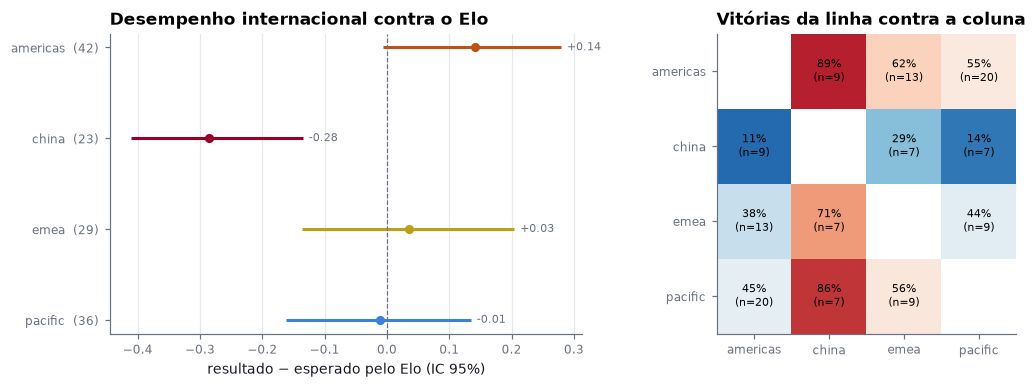

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
e = by_region.excess_over_elo
P.forest(ax1, [f"{r}  ({n})" for r, n in zip(by_region.region, by_region.matches)],
         [x.value for x in e], [x.low for x in e], [x.high for x in e], null=0.0,
         colors=[P.REGION[r] for r in by_region.region], fmt="{:+.2f}")
ax1.set_xlabel("resultado − esperado pelo Elo (IC 95%)")
ax1.set_title("Desempenho internacional contra o Elo")

m = reg["matrix"].assign(rate=lambda d: d["sum"] / d["count"])
regions = sorted(set(m.region) | set(m.opponent_region))
grid = m.pivot(index="region", columns="opponent_region", values="rate").reindex(index=regions, columns=regions)
n = m.pivot(index="region", columns="opponent_region", values="count").reindex(index=regions, columns=regions)
im = ax2.imshow(grid.values, cmap="RdBu_r", vmin=0, vmax=1)
for i in range(len(regions)):
    for j in range(len(regions)):
        if not np.isnan(grid.values[i, j]):
            ax2.text(j, i, f"{grid.values[i, j]:.0%}\n(n={int(n.values[i, j])})",
                     ha="center", va="center", fontsize=7)
ax2.set_xticks(range(len(regions)), regions)
ax2.set_yticks(range(len(regions)), regions)
ax2.grid(False)
ax2.set_title("Vitórias da linha contra a coluna")
fig.tight_layout()
plt.show()

## Conclusão

In [4]:
sig = by_region[by_region.verdict != "inconclusivo"]
lines = [f"- **{r.region}**: {r.verdict}, {r.excess_over_elo.text(3)} em {r.matches} séries"
         for r in sig.itertuples()]
display(Markdown("\n".join([
    f"- {reg['matches']} séries internacionais entre regiões na janela.",
    *lines,
    f"- Inconclusivas: {', '.join(by_region[by_region.verdict == 'inconclusivo'].region)}.",
    "- Região abaixo do Elo nos internacionais = Elo **superestimado** pela liga doméstica. É o "
    "motivo do aviso na tela de previsões: comparação entre regiões vale menos que dentro delas.",
])))

- 65 séries internacionais entre regiões na janela.
- **china**: abaixo do Elo, -0,285 (IC 95% -0,411 a -0,135) em 23 séries
- Inconclusivas: americas, emea, pacific.
- Região abaixo do Elo nos internacionais = Elo **superestimado** pela liga doméstica. É o motivo do aviso na tela de previsões: comparação entre regiões vale menos que dentro delas.